In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import json
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [10]:
ROOT = Path("/content/drive/My Drive/wsp")

URL = "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
AGENT_WEIGHTS = ROOT / "final.weights.h5"

SEQUENCE_LENGTH = 100
HIDDEN_UNITS = 256
BATCH_SIZE = 64

ARMS = ["agent", "random", "shuffled"]
SEEDS = [0, 1, 2]
MAX_EPOCHS = 200  # the random arm was still improving at 60
PATIENCE = 5
TRAIN_PASSAGES = None  # e.g. 500 for a quick check that everything runs; None for all

LN2 = np.log(2)

# Data

In [4]:
text = open(keras.utils.get_file("shakespeare.txt", URL)).read()
vocab = np.array(sorted(set(text)))
ids = np.searchsorted(vocab, list(text))


def passages(ids):
    count = (len(ids) - 1) // SEQUENCE_LENGTH
    end = count * SEQUENCE_LENGTH

    x = ids[:end].reshape(count, SEQUENCE_LENGTH)
    y = ids[1 : end + 1].reshape(count, SEQUENCE_LENGTH)
    return x, y


a, b = int(len(ids) * 0.90), int(len(ids) * 0.95)
x_train, y_train = passages(ids[:a])
x_val, y_val = passages(ids[a:b])
x_test, y_test = passages(ids[b:])

if TRAIN_PASSAGES:
    x_train, y_train = x_train[:TRAIN_PASSAGES], y_train[:TRAIN_PASSAGES]

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# Model

In [5]:
def build_model():
    model = keras.Sequential(
        [
            keras.Input(shape=(None,), dtype="int32"),
            keras.layers.CategoryEncoding(
                len(vocab), output_mode="one_hot", name="one_hot"
            ),
            keras.layers.LSTM(HIDDEN_UNITS, return_sequences=True, name="lstm"),
            keras.layers.Dense(
                len(vocab), name="output"
            ),  # logits: the loss applies the softmax
        ]
    )
    model.compile(
        optimizer="adam",
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

In [6]:
class BatchLosses(keras.callbacks.Callback):
    """
    Records the training loss after every batch of the first epoch, to catch a
    rise at the start of training. Keras reports the running mean over the
    epoch so far, so it is converted back to each batch's own loss.
    """

    def __init__(self):
        super().__init__()
        self.losses = []
        self.epoch = 0
        self.previous_mean = 0.0

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch

    def on_train_batch_end(self, batch, logs=None):
        if self.epoch == 0:
            mean = logs["loss"]
            self.losses.append(mean * (batch + 1) - self.previous_mean * batch)
            self.previous_mean = mean

In [7]:
def shuffle_weights(model, seed):
    """
    Put the values of each weight tensor in a random order. The LSTM tensors
    are shuffled one gate at a time (the last axis holds the gates i, f, g, o
    in blocks of HIDDEN_UNITS), so each gate keeps its own values.
    """
    rng = np.random.default_rng(seed)

    for layer in (model.get_layer("lstm"), model.get_layer("output")):
        shuffled = []
        for w in layer.get_weights():
            blocks = np.split(w, 4, axis=-1) if layer.name == "lstm" else [w]
            blocks = [rng.permutation(b.ravel()).reshape(b.shape) for b in blocks]
            shuffled.append(np.concatenate(blocks, axis=-1))
        layer.set_weights(shuffled)


In [11]:
def train(init, seed):
    # initial weights (random arm), shuffle order (shuffled arm) and batch order (all)
    keras.utils.set_random_seed(seed)
    model = build_model()
    if init in ("agent", "shuffled"):
        model.load_weights(AGENT_WEIGHTS)
    if init == "shuffled":
        shuffle_weights(model, seed)

    loss, accuracy = model.evaluate(x_val, y_val, batch_size=256, verbose=0)
    history = {
        "val_bits": [loss / LN2],
        "val_accuracy": [accuracy],
        "train_bits": [None],
    }

    batches = BatchLosses()
    start = time.time()
    fit = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        batch_size=BATCH_SIZE,
        epochs=MAX_EPOCHS,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
            batches,
        ],
        verbose=2,
    )

    history["val_bits"] += [v / LN2 for v in fit.history["val_loss"]]
    history["val_accuracy"] += fit.history["val_accuracy"]
    history["train_bits"] += [v / LN2 for v in fit.history["loss"]]

    test_loss, test_accuracy = model.evaluate(x_test, y_test, batch_size=256, verbose=0)
    best = int(np.argmin(history["val_bits"]))

    return {
        "init": init,
        "seed": seed,
        **history,
        "first_epoch_batch_bits": [v / LN2 for v in batches.losses],
        "best_epoch": best,
        "best_val_bits": history["val_bits"][best],
        "test_bits": test_loss / LN2,
        "test_accuracy": test_accuracy,
        "seconds": time.time() - start,
    }

# Run

In [12]:
results = []
for seed in SEEDS:
    for init in ARMS:
        print(f"\n=== {init}, seed {seed} ===")
        results.append(train(init, seed))
        r = results[-1]
        print(
            f"{init}, seed {seed}: epoch 0 {r['val_bits'][0]:.3f} bits, "
            f"best {r['best_val_bits']:.3f} at epoch {r['best_epoch']}, "
            f"test {r['test_bits']:.3f} bits, {r['test_accuracy']:.1%}"
        )

        with open(ROOT / "init_comparison.json", "w") as f:
            json.dump(results, f, indent=2)


=== agent, seed 0 ===


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Epoch 1/200
157/157 - 4s - 24ms/step - accuracy: 0.4382 - loss: 1.8885 - val_accuracy: 0.4357 - val_loss: 1.8903
Epoch 2/200
157/157 - 2s - 14ms/step - accuracy: 0.4832 - loss: 1.7337 - val_accuracy: 0.4664 - val_loss: 1.8028
Epoch 3/200
157/157 - 3s - 18ms/step - accuracy: 0.5079 - loss: 1.6387 - val_accuracy: 0.4886 - val_loss: 1.7324
Epoch 4/200
157/157 - 3s - 17ms/step - accuracy: 0.5233 - loss: 1.5798 - val_accuracy: 0.5019 - val_loss: 1.6821
Epoch 5/200
157/157 - 5s - 31ms/step - accuracy: 0.5344 - loss: 1.5380 - val_accuracy: 0.5139 - val_loss: 1.6503
Epoch 6/200
157/157 - 2s - 14ms/step - accuracy: 0.5431 - loss: 1.5064 - val_accuracy: 0.5215 - val_loss: 1.6262
Epoch 7/200
157/157 - 2s - 12ms/step - accuracy: 0.5499 - loss: 1.4812 - val_accuracy: 0.5258 - val_loss: 1.6100
Epoch 8/200
157/157 - 3s - 21ms/step - accuracy: 0.5553 - loss: 1.4606 - val_accuracy: 0.5296 - val_loss: 1.5966
Epoch 9/200
157/157 - 2s - 12ms/step - accuracy: 0.5599 - loss: 1.4430 - val_accuracy: 0.5328 - 

# Summary

In [13]:
def first_epoch_below(r, bits):
    """
    The first epoch whose validation score is at or below `bits`, or None.
    """
    return next((e for e, v in enumerate(r["val_bits"]) if v <= bits), None)


print(
    f"\n{'':18}{'epoch 0':>9}{'epoch 1':>9}{'epoch 6':>9}{'best':>9}{'at':>5}"
    f"{'test':>9}{'acc':>8}{'<=2.91':>8}{'<=2.50':>8}"
)
for r in results:
    v = r["val_bits"]
    at = lambda e: f"{v[e]:9.3f}" if e < len(v) else f"{'-':>9}"
    hit = lambda bits: first_epoch_below(r, bits)
    print(
        f"{r['init'] + ', seed ' + str(r['seed']):18}{at(0)}{at(1)}{at(6)}"
        f"{r['best_val_bits']:9.3f}{r['best_epoch']:5}{r['test_bits']:9.3f}"
        f"{r['test_accuracy']:8.1%}{str(hit(2.91)):>8}{str(hit(2.50)):>8}"
    )
print(
    "\n<=2.91: first epoch at the 6-epoch baseline's validation score; "
    "<=2.50: first epoch near convergence. Validation bits throughout."
)


                    epoch 0  epoch 1  epoch 6     best   at     test     acc  <=2.91  <=2.50
agent, seed 0         3.019    2.727    2.346    2.207   22    2.498   52.2%       1       3
random, seed 0        6.018    3.867    2.917    2.237   63    2.470   51.5%       7      19
shuffled, seed 0      9.183    3.823    2.759    2.255   44    2.676   51.1%       5      13
agent, seed 1         3.019    2.722    2.340    2.193   27    2.477   52.4%       1       3
random, seed 1        6.027    3.970    2.941    2.240   59    2.449   51.4%       7      20
shuffled, seed 1      8.352    3.805    2.813    2.271   42    2.611   51.4%       5      14
agent, seed 2         3.019    2.724    2.336    2.199   25    2.458   52.6%       1       3
random, seed 2        6.027    3.901    2.930    2.221   58    2.437   51.4%       7      19
shuffled, seed 2     10.289    4.348    3.053    2.263   63    2.739   51.8%       8      18

<=2.91: first epoch at the 6-epoch baseline's validation score; <=2.

# Plots

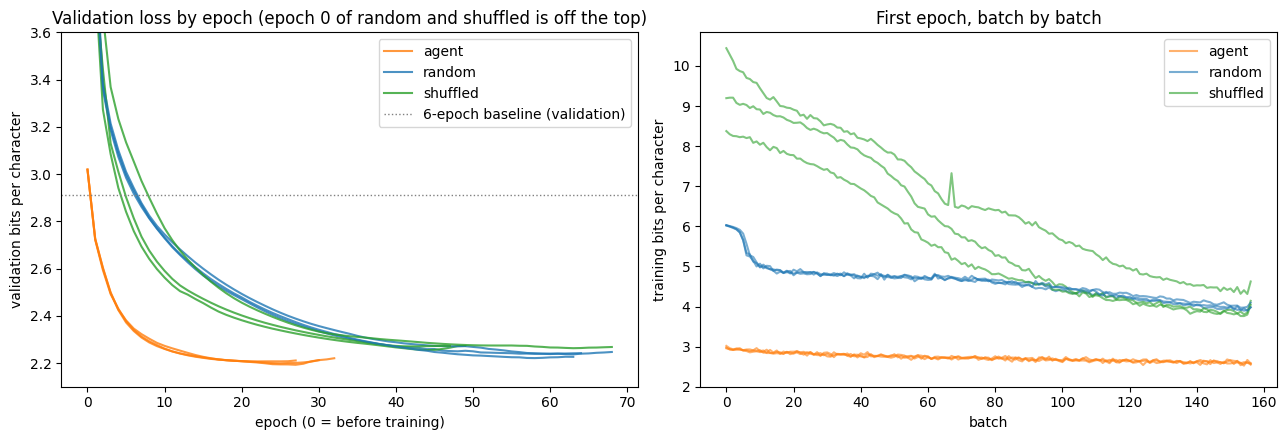

In [14]:
colours = {"agent": "tab:orange", "random": "tab:blue", "shuffled": "tab:green"}
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))

for r in results:
    label = r["init"] if r["seed"] == SEEDS[0] else None
    left.plot(r["val_bits"], color=colours[r["init"]], alpha=0.8, label=label)
    right.plot(
        r["first_epoch_batch_bits"], color=colours[r["init"]], alpha=0.6, label=label
    )

left.axhline(2.910, color="grey", ls=":", lw=1, label="6-epoch baseline (validation)")
left.set(
    xlabel="epoch (0 = before training)",
    ylabel="validation bits per character",
    title="Validation loss by epoch (epoch 0 of random and shuffled is off the top)",
    ylim=(2.1, 3.6),
)
left.legend()

right.set(
    xlabel="batch",
    ylabel="training bits per character",
    title="First epoch, batch by batch",
)
right.set_ylim(bottom=2.0)  # no top limit: the shuffled arm may start far above 6
right.legend()

plt.tight_layout()
plt.savefig(ROOT / "init_comparison.png", dpi=120)
plt.show()
